# nb01 · L0 数值参考一致性

**目的**（`validation_methods_L0-L5.md` L0）：找出模型在目标构型上 energy / force / stress 的失效环境。

第一阶段要求的六件事，本 notebook 逐条落地：

1. energy/force/stress 的 MAE、RMSE、P99、max；
2. 能量按同组成去掉常数偏移后再比；
3. 力误差按元素、力幅、温度段、构型类型分箱；
4. 导出误差最大的帧和原子，并保留原结构；
5. 标记参考协议、模型原生协议与数据泄漏风险；
6. 应力的符号、单位与来源核实之后才进入计分。

被测模型 **MACE-MPA-0 (medium)**。参考数据只来自 phase-1 的 DFT 任务，分成**两套职责不同的标签**：

| 标签集 | 内容 | 角色 | 用途 |
|---|---|---|---|
| **H5** | 从 canonical AIMD 链抽取的 120 帧 306 原子构型，canonical 静态协议重算 | `protected_audit` | L0 **打分**；不导出、不指导补数据 |
| **诊断集** | L1/L2/H1/H2 晶体任务的全部离子步（3726 帧） | `diagnostic` | 定位失效、**导出补算候选** |

> 2026-11-02 起旧的 615 帧（`gst225_legacy_static_v0`）与 bridge set 退役：两套新标签与 L1–L5 的
> AIMD 参考用同一套电子设置，`d_protocol` 按构造为 0，不再需要单独量化协议差。

In [1]:
import os
# per-model results/data (results/models/<key>/); without it mlipeval falls back to the
# flat pre-2026-09 layout, which no longer holds current results
os.environ.setdefault("MLIPEVAL_MODEL", "mace_mpa0")
import sys, json
sys.path.insert(0, "../scripts")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mlipeval import datasets, models, paths, protocols
from mlipeval.cache import cached_predict
from mlipeval.calculators import model_spec_only
from mlipeval.l0_reference import evaluate_l0
from mlipeval.plotting import binned_error_panel, error_hist_panel, parity_panel, use_style

use_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 64)

## 1. 参考数据、角色与溯源

L0 的每一个数字都属于某一个 `protocol_id` 和某一个数据角色。`database_link.md` 3.1 禁止把不同协议的
标签汇进同一个 RMSE，3.5 要求每帧标 `training` / `diagnostic` / `protected_audit` 三选一。
所以第一步不是算误差，而是把两套参考数据的身份钉死。

In [2]:
inv = datasets.inventory()
display(inv)

h5 = datasets.labelled_h5()
diag = datasets.labelled_diagnostic()
display(pd.DataFrame([{
    "标签集": name, "帧数": len(s), "protocol_id": s.protocol_id, "角色": s.role.value,
    "原子数": ", ".join(sorted({str(n) for n in s.n_atoms})) if len(set(s.n_atoms)) <= 4 else
            f"{int(min(s.n_atoms))}-{int(max(s.n_atoms))}",
    "带应力的帧": int(s.stresses()[0].sum()) if s.stresses() is not None else 0,
} for name, s in (("H5", h5), ("diagnostic", diag))]).set_index("标签集"))
print("H5   :", h5.notes)
print("诊断集:", diag.notes)

,dataset,protocol_id,available,detail
0,aimd_306/liquid_2000K,gst225_legacy_aimd_306_v0,False,RETIRED 2026-11-02 (no INCAR stored; density 0.02852 at/A^3)
1,aimd_306/quench,gst225_legacy_aimd_306_v0,False,RETIRED 2026-11-02 (no INCAR stored; density 0.02852 at/A^3)
2,aimd_306/relax_300K,gst225_legacy_aimd_306_v0,False,RETIRED 2026-11-02 (no INCAR stored; density 0.02852 at/A^3)
3,aimd_216/melt_2000K,gst225_legacy_aimd_216_v0,False,RETIRED 2026-11-02 (SMASS=-1 velocity scaling)
4,aimd_216/quench_2000_300K,gst225_legacy_aimd_216_v0,False,RETIRED 2026-11-02 (SMASS=-1 velocity scaling)
5,aimd_216/relax,gst225_legacy_aimd_216_v0,False,RETIRED 2026-11-02 (SMASS=-1 velocity scaling)
6,aimd_216/amorphous_300K_a,gst225_legacy_aimd_216_v0,False,RETIRED 2026-11-02 (SMASS=-1 velocity scaling)
7,aimd_216/amorphous_300K_b,gst225_legacy_aimd_216_v0,False,RETIRED 2026-11-02 (SMASS=-1 velocity scaling)
8,preflight/nvt_3000K,gst225_aimd_canonical_v1,True,"canonical protocol, but only 67-333 steps"
9,preflight/nvt_1200K,gst225_aimd_canonical_v1,True,"canonical protocol, but only 67-333 steps"


,帧数,protocol_id,角色,原子数,带应力的帧
标签集,,,,,
H5,120,gst225_pbe_canonical_v1,protected_audit,306,120
diagnostic,3726,gst225_pbe_canonical_v1,diagnostic,"194, 2, 3, 9",2996


H5   : 120 static relabels of phase-1 canonical AIMD frames (306-atom Ge68Sb68Te170, 0.0309 at/A^3): 30 from the 950 K production runs, 30 from the 300->1200 K heating ramps, 60 from the melt-quench chains (melt / 1200 K liquid / quench / 300 K production, 5 per stage per seed).
诊断集: crystalline phase-1 tasks under the canonical static protocol: L1 MP cells, L2 element references and H1 cubic seeds (static + every relaxation step) and the 42 H2 fixed-volume EOS relaxations. Stress only on fixed-cell frames.


### H5：从哪条链、哪个阶段抽的

每帧都记着来源任务、种子与源帧号，所以 L0 的误差可以直接对回 L3–L5 用的同一批 AIMD 链。
`pool` 是抽样池（链上的阶段），`state_kind` 是它对应的状态点。

In [3]:
display(pd.crosstab(h5.tags["pool"], h5.tags["seed"], margins=True, margins_name="合计")
        .rename_axis(index="pool", columns="seed"))
display(pd.crosstab(h5.tags["state_kind"], h5.tags["pool"]))

seed,1,2,3,合计
pool,,,,
heat,10,10,10,30
liquid1200,5,5,5,15
md950,10,10,10,30
melt3000,5,5,5,15
prod300,5,5,5,15
quench,5,5,5,15
合计,40,40,40,120


col_0,heat,liquid1200,md950,melt3000,prod300,quench
row_0,,,,,,
amorphous_300K,0,0,0,0,15,0
heating_300_1200K,30,0,0,0,0,0
liquid_1200K,0,15,0,0,0,0
liquid_3000K,0,0,0,15,0,0
liquid_950K,0,0,30,0,0,0
quench_1200_300K,0,0,0,0,0,15


### 诊断集：晶体相的全部离子步

固定晶胞的任务（静态单点、H2 定体积 EOS）带应力；变晶胞弛豫（ISIF=3）的中间步只用能量与力——
Pulay 应力让弛豫途中的应力不能当参考。

In [4]:
stress_mask = diag.stresses()[0]
display(pd.DataFrame({"帧数": pd.Series(diag.tags["subset"]).value_counts(),
                      "带应力": pd.Series(diag.tags["subset"][stress_mask]).value_counts()})
        .fillna(0).astype(int).sort_index())
print("组成:", dict(pd.Series(diag.compositions()).value_counts()))

,帧数,带应力
eos_cubic,2723,2723
eos_hex,262,262
relax_cubic,533,0
relax_element,49,0
relax_mp,148,0
static_cubic,5,5
static_element,3,3
static_mp,3,3


组成: {'Ge43Sb43Te108': np.int64(3261), 'Ge2Sb2Te5': np.int64(413), 'Te3': np.int64(25), 'Sb2': np.int64(21), 'Ge2': np.int64(6)}


### 协议：两套标签与 AIMD 参考是同一套电子设置

`compare_protocols` 只列出**改变物理量**的差异（它会把 `NSW`/`IBRION` 这类对静态与 MD 天然不同、
但不改变能量面的开关归为惰性）。两套 L0 标签都是 `gst225_pbe_canonical_v1`，
与 L1–L5 的 AIMD 参考 `gst225_aimd_canonical_v1` 比较，剩下的只有 MD 本身的开关。

In [5]:
delta = protocols.compare_protocols(protocols.canonical_static(), protocols.canonical_aimd())
print("同一 PAW 文件 :", delta["same_paw_dataset"])
print("比较时排除    :", delta["tags_ignored_as_inert"])
print("物理差异      :", delta["verdict"])
if delta["differences"]:
    display(pd.DataFrame(delta["differences"]).T)

同一 PAW 文件 : True
比较时排除    : []
物理差异      : 14 physics-relevant differences: ADDGRID, ALGO, EDIFF, ENCUT, IBRION, ISYM, KSPACING, MDALGO, NSW, POTIM, SMASS, SYMPREC, TEBEG, TEEND


,gst225_pbe_canonical_v1,gst225_aimd_canonical_v1
ENCUT,500,300
EDIFF,1E-07,1E-05
ALGO,FAST,VERYFAST
KSPACING,0.20,(UNSET)
ISYM,-1,0
SYMPREC,1E-4,1E-5
ADDGRID,TRUE,FALSE
NSW,0,67
IBRION,-1,0
POTIM,(UNSET),3.0


## 2. 泄漏筛查

两套标签各自有一份 sha256 绑定的筛查记录：文件一改，记录即失效，角色也随之作废。

- **H5** 必须对工作区里**所有** GST 训练集无命中才能获得 `protected_audit`；
- **诊断集** 不要求干净，但要逐帧记下每个训练集覆盖了哪些帧——评某个模型时先把它见过的帧剔除。

筛查用总 RDF 指纹，组成按**约化化学式**匹配（这样 18 原子超胞也会被比到 9 原子原胞上）。
命中意味着"去看一眼"，不等于"完全相同"。

In [6]:
screen_h5 = json.loads(paths.H5_LEAKAGE.read_text())
print(f"H5 筛查: verdict={screen_h5['verdict']}  阈值={screen_h5['threshold_rdf']}  "
      f"sha256={screen_h5['sha256'][:12]}  ({screen_h5['screened_at']})")
display(pd.DataFrame(screen_h5["rows"]))

screen_d = json.loads(paths.DIAGNOSTIC_LEAKAGE.read_text())
overlap = pd.DataFrame([{
    "训练集": name, "训练集帧数": entry["n_frames"],
    "覆盖的诊断帧": len(entry["overlapping_frames"]),
    "涉及任务": ", ".join(sorted({f.split(":")[0] for f in entry["overlapping_frames"]})),
} for name, entry in screen_d["training_sets"].items()]).set_index("训练集")
display(overlap)

seen = datasets.diagnostic_training_overlap(diag, models.current_key())
print(f"\n当前模型 {models.current_key()}: 诊断集里有 {int(seen.sum())} 帧在其训练集中，评估前剔除")
if seen.any():
    diag = diag.subset(~seen)

H5 筛查: verdict=clean  阈值=0.02  sha256=297569b0b6a7  (2026-10-27T14:22:06)


,training_set,n_frames,composition_matches,V_per_atom_median,nearest_rdf,verdict
0,GST-ACE-24,4636,0,NaN,NaN,clean (no composition match)
1,processed_NE,2528,0,NaN,NaN,clean (no composition match)
2,"spec splits (gst_*, gst_ne_*)",7161,0,NaN,NaN,clean (no composition match)
3,GST225-aging,4577,70,39.004,0.1163,clean
4,AL gen0,422,0,NaN,NaN,clean (no composition match)
5,AL gen3,780,0,NaN,NaN,clean (no composition match)
6,AL gen4,1060,0,NaN,NaN,clean (no composition match)
7,AL gen6,1013,112,40.687,0.1156,clean
8,AL gen7,1161,112,40.687,0.1156,clean
9,AL gen8,701,55,38.265,0.1163,clean


,训练集帧数,覆盖的诊断帧,涉及任务
训练集,,,
GST-ACE-24,4636,13,"L1_mp1224375_relax, L1_mp1224407_relax, L2_ge_relax, L2_sb_r..."
processed_NE,2528,13,"L1_mp1224375_relax, L1_mp1224407_relax, L2_ge_relax, L2_sb_r..."
GST225-aging,4577,13,"L1_mp1224375_relax, L1_mp1224407_relax, L2_ge_relax, L2_sb_r..."
AL gen0,422,0,
AL gen3,780,0,
AL gen4,1060,0,
AL gen6,1013,0,
AL gen7,1161,0,
AL gen8,701,0,



当前模型 mace_mpa0: 诊断集里有 0 帧在其训练集中，评估前剔除


## 3. 固定被测模型

任何会改变数值的开关都要钉死：checkpoint 的 sha256、dtype、device、随机种子、软件版本。
`ModelSpec` 把这些一次性捕获，之后每条 metric 都带着它。

In [7]:
# Read-only path: the pinned identity is all a cache lookup needs, so the
# notebook never loads the network and never evaluates anything here.
# The numbers themselves were produced by the PBS job (submit_pbs.py --chain).
model = model_spec_only()
spec = model.to_dict()
display(pd.Series({
    "name": spec["name"],
    "checkpoint sha256": spec["checkpoint_sha256"],
    "dtype": spec["dtype"], "device": spec["device"], "seed": spec["seed"],
    "原生理论层级": spec["native_protocol"], "dispersion": spec["dispersion"],
    **{f"version/{k}": v for k, v in spec["software"].items() if k in ("mace", "torch", "ase", "numpy")},
}).to_frame("value"))

,value
name,MACE-MPA-0 (medium)
checkpoint sha256,75428afe3a1d7d8062e19bcaabd5c433623cabf308242ec9fb493e38604f...
dtype,float64
device,cpu
seed,0
原生理论层级,"PBE+U (MPtrj + sAlex), no dispersion"
dispersion,False
version/numpy,2.4.2
version/ase,3.27.0
version/torch,2.10.0


## 4. H5：L0 打分

预测从缓存读取（PBS 作业里的 `run_l0.py` 写入），本 notebook 不加载网络。
下面用同一批预测重算一遍，并与 `run_l0.py` 写出的 `L0_audit.json` 逐条核对——
notebook 展示的数字必须就是计分用的数字。

In [8]:
pred_h5 = cached_predict(h5.frames, model, tag=f"L0_h5_{len(h5)}")
print(f"{len(pred_h5)} 帧预测，耗时 {pred_h5.wall_time_s:.0f} s，失败 {len(pred_h5.failures)} 帧")

report = evaluate_l0(
    h5, model, predictions=pred_h5,
    tags={k: h5.tags[k] for k in ("pool", "state_kind")},
    leakage_note=f"H5 screened '{screen_h5['verdict']}' (sha256 {screen_h5['sha256'][:12]})",
)
print(f"共产出 {len(report.results)} 条 metric")

saved = {r["metric_id"]: r["value"] for r in
         json.loads(paths.result_path("L0_audit.json").read_text())["results"]}
mine = {r.metric_id: r.value for r in report.results}
mismatch = [k for k in saved if k in mine and isinstance(saved[k], float)
            and not np.isclose(saved[k], mine[k], rtol=1e-9, atol=1e-12)]
print(f"与 L0_audit.json 对照: {len(set(saved) & set(mine))} 条共有，{len(mismatch)} 条不一致")

[cache] reusing L0_h5_120__75428afe3a__cuda_float64__mace-mpa-0-medium.model__00eb0021a00d7e2e.npz
        (written on a different device; float64 CPU/GPU agree bit-for-bit here)
120 帧预测，耗时 6 s，失败 0 帧
共产出 49 条 metric
与 L0_audit.json 对照: 49 条共有，0 条不一致


## 5. 能量：先去掉同组成常数偏移

`database_link.md` 3.4 只允许在**同组成、同协议**内去掉一个常数偏移，别的经验校正一律禁止。
这里的偏移按"每原子"拟合：`E_model - n_atoms · offset` 在均值意义上对齐 `E_ref`。

这一步是必须的，因为 MACE-MPA-0 的能量零点来自 MPtrj/sAlex 的 PBE+U 参考态，
与本项目 PBE 的零点没有可比性；但**偏移之后的离散度**是真正的模型误差。
H5 只有一种组成（Ge68Sb68Te170），所以偏移没有自由度歧义。

每组成常数偏移 (eV/atom): {'Ge68Sb68Te170': -0.026456}


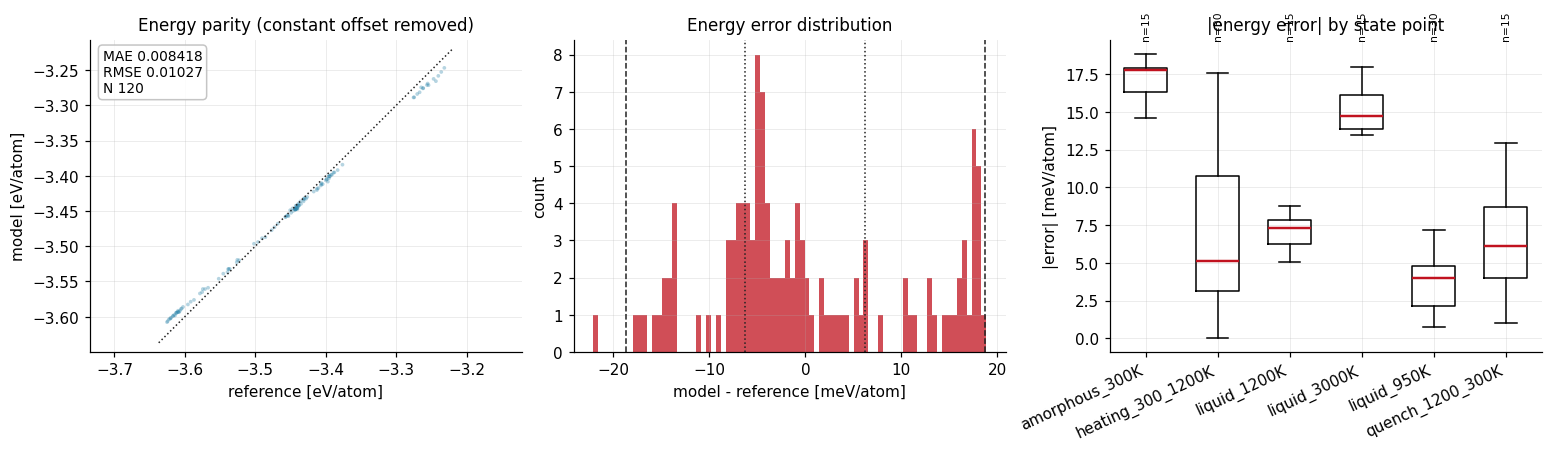

,metric_id,value,unit,status,tier,grade,z_eff
2,L0.energy_mae,8.417543,meV/atom,provisional,B,ungraded,None
3,L0.energy_rmse,10.269024,meV/atom,provisional,B,ungraded,None
4,L0.energy_p99,18.703354,meV/atom,provisional,B,ungraded,None
5,L0.energy_max,22.083829,meV/atom,provisional,B,ungraded,None
6,L0.energy_offset_spread,0.0,meV/atom,ok,S,ungraded,None
27,L0.energy_mae.pool=heat,6.761294,meV/atom,provisional,B,ungraded,None
28,L0.energy_mae.pool=liquid1200,7.304416,meV/atom,provisional,B,ungraded,None
29,L0.energy_mae.pool=md950,3.524498,meV/atom,provisional,B,ungraded,None
30,L0.energy_mae.pool=melt3000,15.165645,meV/atom,provisional,B,ungraded,None
31,L0.energy_mae.pool=prod300,17.117182,meV/atom,provisional,B,ungraded,None


In [9]:
offsets = report.offsets
print("每组成常数偏移 (eV/atom):", {k: round(v, 6) for k, v in offsets.items()})

fig, axes = plt.subplots(1, 3, figsize=(14, 4.0))
n_at = h5.n_atoms
parity_panel(axes[0], report.energy_ref / n_at, report.energy_model_shifted / n_at,
             unit="eV/atom", title="Energy parity (constant offset removed)")
error_hist_panel(axes[1], report.energy_error_per_atom * 1000.0,
                 unit="meV/atom", title="Energy error distribution")

state = h5.tags["state_kind"]
groups = {s: report.energy_error_per_atom[state == s] * 1000.0 for s in np.unique(state)}
binned_error_panel(axes[2], groups, unit="meV/atom", title="|energy error| by state point")
plt.setp(axes[2].get_xticklabels(), rotation=25, ha="right")
plt.show()

display(report.results.to_frame().query("metric_id.str.startswith('L0.energy')"))

（读图结论在执行后填写。）

## 6. 力：整体、分元素、分力幅、分状态点

力是 L0 里最能定位问题的量，因为它逐原子可归因。四种分箱回答四个不同的问题：

| 分箱 | 回答 |
|---|---|
| 元素 | 哪个元素的局域环境学得差 |
| 力幅 \|F\| | 误差是均匀的还是集中在强受力（近距/高应变）原子上 |
| 状态点 | 误差随温度/无序度怎么变（950 K、1200 K、3000 K 液体，升温、淬火，300 K 非晶） |

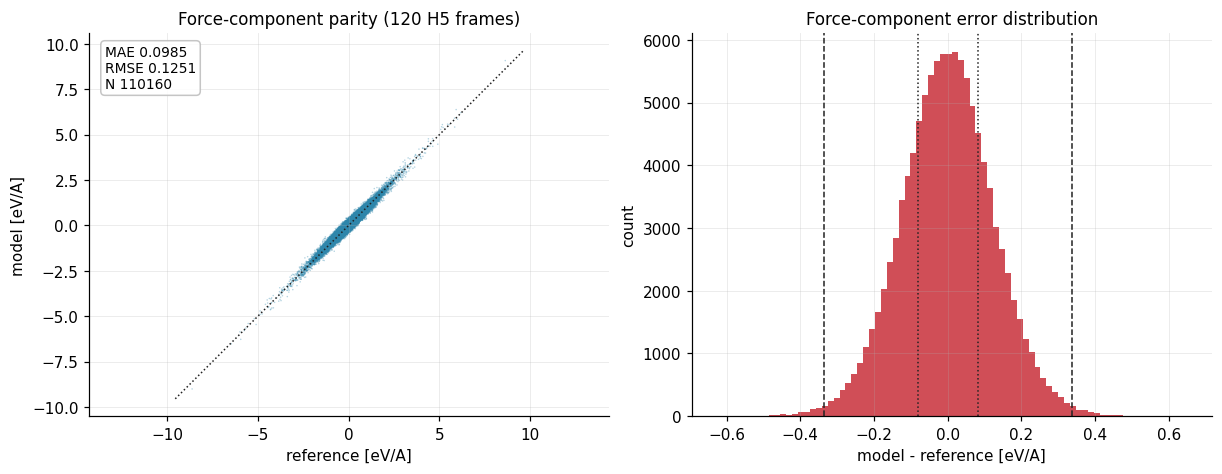

,metric_id,value,unit,status,tier,grade,z_eff
7,L0.force_mae,0.098496,eV/A,provisional,B,ungraded,None
8,L0.force_rmse,0.125129,eV/A,provisional,B,ungraded,None
9,L0.force_p99,0.33693,eV/A,provisional,B,ungraded,None
10,L0.force_max,0.652978,eV/A,provisional,B,ungraded,None
11,L0.force_component_r2,0.949515,-,ok,B,ungraded,None
12,L0.force_mae.species=Ge,0.094021,eV/A,provisional,B,ungraded,None
13,L0.force_mae.species=Sb,0.100088,eV/A,provisional,B,ungraded,None
14,L0.force_mae.species=Te,0.09965,eV/A,provisional,B,ungraded,None
21,L0.force_rmse.pool=heat,0.118209,eV/A,provisional,B,ungraded,None
22,L0.force_rmse.pool=liquid1200,0.130901,eV/A,provisional,B,ungraded,None


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
parity_panel(axes[0], report.force_ref_flat, report.force_model_flat,
             unit="eV/A", title=f"Force-component parity ({len(h5)} H5 frames)", s=1)
error_hist_panel(axes[1], report.force_model_flat - report.force_ref_flat,
                 unit="eV/A", title="Force-component error distribution")
plt.show()

display(report.results.to_frame().query(
    "metric_id.str.startswith('L0.force_mae') or metric_id.str.startswith('L0.force_rmse') "
    "or metric_id.str.startswith('L0.force_p99') or metric_id.str.startswith('L0.force_max') "
    "or metric_id == 'L0.force_component_r2'"))

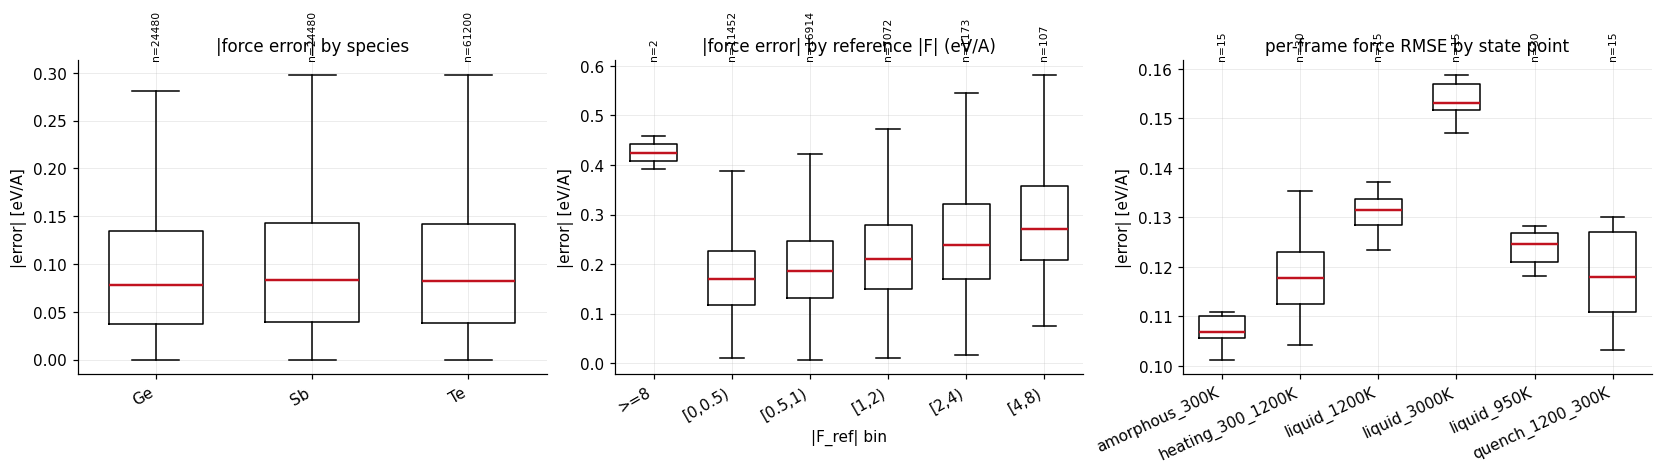

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
binned_error_panel(axes[0], report.force_error_by_species, unit="eV/A", title="|force error| by species")
binned_error_panel(axes[1], report.force_error_by_magnitude, unit="eV/A",
                   title="|force error| by reference |F| (eV/A)", metric=lambda x: x)
axes[1].set_xlabel("|F_ref| bin")
binned_error_panel(axes[2], report.force_error_by_tag["state_kind"], unit="eV/A",
                   title="per-frame force RMSE by state point", metric=lambda x: x)
plt.setp(axes[2].get_xticklabels(), rotation=25, ha="right")
plt.show()

,|F| 区间,样本数,MAE (eV/A),区间中点 |F| (eV/A),相对误差
0,>=8,2,0.4248,8.25,0.0515
1,"[0,0.5)",11452,0.1778,0.25,0.7112
2,"[0.5,1)",16914,0.1945,0.75,0.2593
3,"[1,2)",7072,0.2218,1.50,0.1479
4,"[2,4)",1173,0.2522,3.00,0.0841
5,"[4,8)",107,0.2959,6.00,0.0493


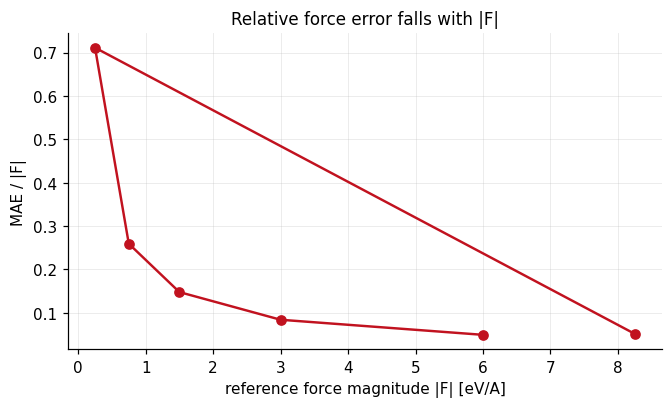

In [12]:
# 相对误差视角：绝对误差随 |F| 增大，但相对误差是否也在恶化？
edges = [0.0, 0.5, 1.0, 2.0, 4.0, 8.0]
rows = []
for label, err in report.force_error_by_magnitude.items():
    lo = float(label.strip("[)>=").split(",")[0])
    hi = lo if ">" in label else float(label.rstrip(")").split(",")[1])
    mid = lo + 0.25 if ">" in label else 0.5 * (lo + hi)
    rows.append({"|F| 区间": label, "样本数": err.size,
                 "MAE (eV/A)": err.mean(),
                 "区间中点 |F| (eV/A)": mid,
                 "相对误差": err.mean() / max(mid, 1e-6)})
mag = pd.DataFrame(rows)
display(mag.round(4))

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(mag["区间中点 |F| (eV/A)"], mag["相对误差"], "o-", color="#c1121f")
ax.set_xlabel("reference force magnitude |F| [eV/A]"); ax.set_ylabel("MAE / |F|")
ax.set_title("Relative force error falls with |F|")
plt.show()

## 7. 应力：直接取自 OUTCAR

H5 与诊断集都是 harvest 时直接从 OUTCAR 读出应力（`REF_stress`，ASE 符号约定，eV/Å³），
不再经过 extxyz 里 `Virial` 的符号推断——旧 615 帧需要的 Virial 约定审计因此不再必要，
应力 metric 从 tier C 升为 **tier B**（项目自算、协议一致的静态 DFT）。

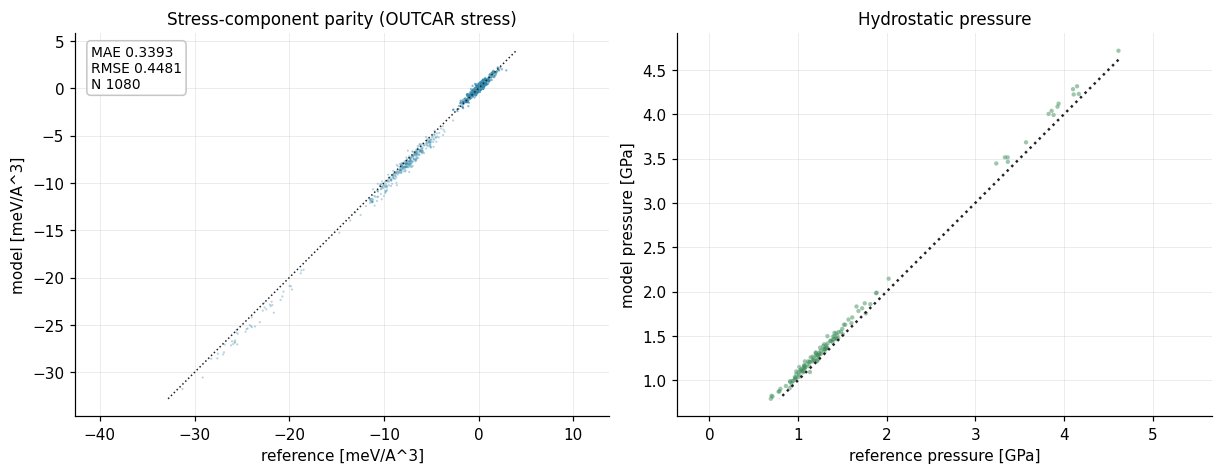

,metric_id,value,unit,status,tier,grade,z_eff
45,L0.stress_mae,0.339261,meV/A^3,provisional,B,ungraded,None
46,L0.stress_rmse,0.448089,meV/A^3,provisional,B,ungraded,None
47,L0.stress_max,2.074421,meV/A^3,provisional,B,ungraded,None


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
parity_panel(axes[0], report.stress_ref.reshape(-1) * 1000, report.stress_model.reshape(-1) * 1000,
             unit="meV/A^3", title="Stress-component parity (OUTCAR stress)", s=2)

diag_ref = np.trace(report.stress_ref, axis1=1, axis2=2) / 3.0
diag_model = np.trace(report.stress_model, axis1=1, axis2=2) / 3.0
from ase.units import GPa
axes[1].scatter(-diag_ref / GPa, -diag_model / GPa, s=8, alpha=0.5, color="#3f8f5b", edgecolors="none")
lim = [min(-diag_ref.min(), -diag_model.min()) / GPa, max(-diag_ref.max(), -diag_model.max()) / GPa]
axes[1].plot(lim, lim, ":", color="#222")
axes[1].set_xlabel("reference pressure [GPa]"); axes[1].set_ylabel("model pressure [GPa]")
axes[1].set_title("Hydrostatic pressure")
axes[1].set_aspect("equal", adjustable="datalim")
plt.show()

display(report.results.to_frame().query("metric_id.str.startswith('L0.stress')"))

## 8. 最差帧与最差原子：只诊断，不导出

L0 的验收条件之一是"能定位到具体异常原子和构型"。`worst_cases` 同时给出两个层面：
按帧的最大逐原子力误差、以及全局最差的单个原子（带元素与帧号）。

H5 是 `protected_audit`：这里**可以看**哪些帧最差、它们来自哪条链的哪个阶段，
但**不能**把它们（或它们的近邻帧）送去补算——一旦被用来指导补数据，H5 就不再是独立的考卷。
补算候选只从第 9 节的诊断集导出。

,帧号,state_kind,pool,seed,源帧,最大逐原子力误差 (eV/A)
0,86,liquid_3000K,melt3000,2,1199,0.853587
1,108,liquid_3000K,melt3000,3,2099,0.769365
2,107,liquid_3000K,melt3000,3,1439,0.736398
3,84,liquid_1200K,liquid1200,2,8599,0.683370
4,105,liquid_3000K,melt3000,3,299,0.683361
5,67,liquid_3000K,melt3000,1,1180,0.677780
6,85,liquid_3000K,melt3000,2,299,0.675947
7,65,liquid_3000K,melt3000,1,235,0.667996
8,68,liquid_3000K,melt3000,1,1464,0.659639
9,103,liquid_1200K,liquid1200,3,7199,0.653678


,帧号,原子序号,元素,力误差 (eV/A)
0,86,64,Ge,0.853587
1,86,303,Te,0.811407
2,108,101,Sb,0.769365
3,107,206,Te,0.736398
4,86,245,Te,0.696219
5,84,27,Ge,0.683370
6,105,162,Te,0.683361
7,67,291,Te,0.677780
8,85,101,Sb,0.675947
9,65,272,Te,0.667996


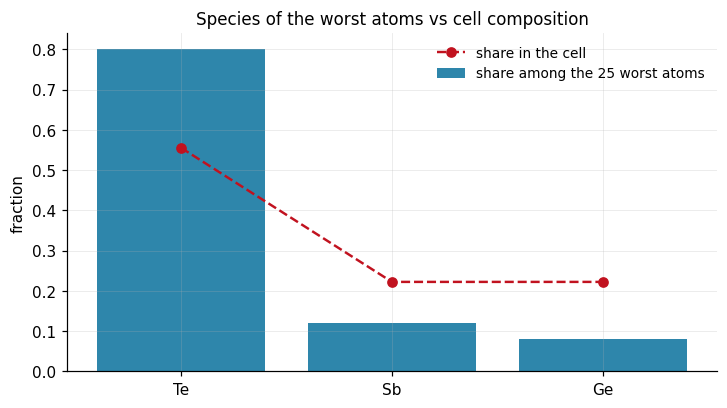

In [14]:
worst = report.worst
frames_df = pd.DataFrame([{
    "帧号": int(i),
    "state_kind": h5.tags["state_kind"][int(i)],
    "pool": h5.tags["pool"][int(i)],
    "seed": int(h5.tags["seed"][int(i)]),
    "源帧": int(h5.tags["source_frame"][int(i)]),
    "最大逐原子力误差 (eV/A)": float(s),
} for i, s in zip(worst.frame_indices, worst.frame_scores)])
display(frames_df)

atoms_df = pd.DataFrame([{
    "帧号": int(f), "原子序号": int(a), "元素": str(sp), "力误差 (eV/A)": float(s),
} for f, a, sp, s in zip(worst.atom_frames, worst.atom_indices, worst.atom_species, worst.atom_scores)])
display(atoms_df.head(15))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
counts = atoms_df["元素"].value_counts()
composition = pd.Series({s: int((np.asarray(h5.symbols()[0]) == s).sum()) for s in counts.index})
ax.bar(counts.index, counts.values / counts.sum(), color="#2e86ab",
       label=f"share among the {len(atoms_df)} worst atoms")
ax.plot(composition.index, composition.values / composition.sum(), "o--", color="#c1121f",
        label="share in the cell")
ax.set_ylabel("fraction"); ax.set_title("Species of the worst atoms vs cell composition")
ax.legend()
plt.show()

## 9. 诊断集：晶体相上的误差，以及补算候选

诊断集覆盖 L2 用到的全部晶体结构：四个 MP 相、立方相五种空位排布、三个单质，以及六方/立方的定体积 EOS。
它和 H5 互补——H5 问"无序态打得准不准"，诊断集问"有序相与弛豫路径上哪里失效"。
多种组成并存，所以常数偏移按组成分别去掉。

[cache] reusing L0_diagnostic_3726__75428afe3a__cuda_float64__mace-mpa-0-medium.model__4ee941ef239ba8d0.npz
        (written on a different device; float64 CPU/GPU agree bit-for-bit here)
3726 帧预测，失败 0 帧
每组成常数偏移 (eV/atom): {'Ge2': -0.11384, 'Ge2Sb2Te5': -0.01531, 'Ge43Sb43Te108': -0.0226, 'Sb2': 0.03161, 'Te3': 0.06115}


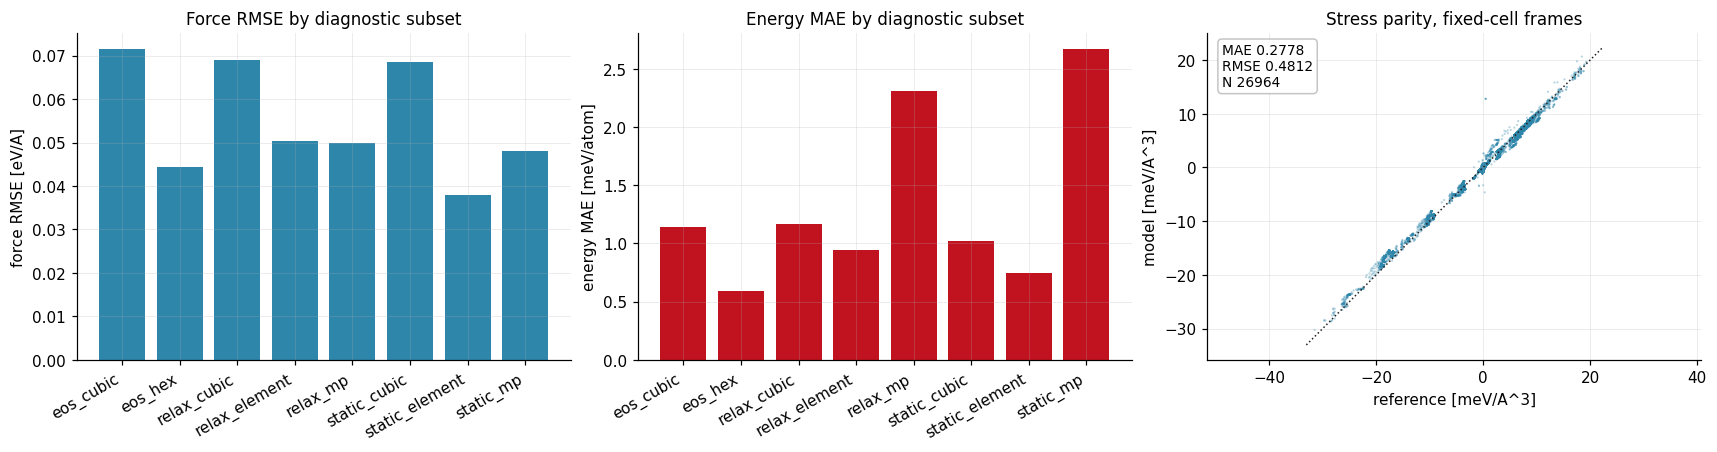

,metric_id,value,unit,status,tier,grade,z_eff
0,L0.model_eval_failures,0,count,ok,S,ungraded,None
1,L0.nonfinite_energies,0,count,ok,S,ungraded,None
2,L0.energy_mae,1.151458,meV/atom,provisional,B,ungraded,None
3,L0.energy_rmse,1.466695,meV/atom,provisional,B,ungraded,None
4,L0.energy_p99,5.169158,meV/atom,provisional,B,ungraded,None
5,L0.energy_max,14.763185,meV/atom,provisional,B,ungraded,None
6,L0.energy_offset_spread,174.983937,meV/atom,ok,S,ungraded,None
7,L0.force_mae,0.055675,eV/A,provisional,B,ungraded,None
8,L0.force_rmse,0.071252,eV/A,provisional,B,ungraded,None
9,L0.force_p99,0.197505,eV/A,provisional,B,ungraded,None


In [15]:
pred_d = cached_predict(diag.frames, model, tag=f"L0_diagnostic_{len(diag)}")
print(f"{len(pred_d)} 帧预测，失败 {len(pred_d.failures)} 帧")
report_d = evaluate_l0(diag, model, predictions=pred_d, tags={"subset": diag.tags["subset"]})
print("每组成常数偏移 (eV/atom):", {k: round(v, 5) for k, v in report_d.offsets.items()})

frame_d = report_d.results.to_frame().set_index("metric_id")
subsets = sorted(np.unique(diag.tags["subset"]))
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.0))
axes[0].bar(subsets, [frame_d.loc[f"L0.force_rmse.subset={s}", "value"] for s in subsets], color="#2e86ab")
axes[0].set_ylabel("force RMSE [eV/A]"); axes[0].set_title("Force RMSE by diagnostic subset")
axes[1].bar(subsets, [frame_d.loc[f"L0.energy_mae.subset={s}", "value"] for s in subsets], color="#c1121f")
axes[1].set_ylabel("energy MAE [meV/atom]"); axes[1].set_title("Energy MAE by diagnostic subset")
for ax in axes[:2]:
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
parity_panel(axes[2], report_d.stress_ref.reshape(-1) * 1000, report_d.stress_model.reshape(-1) * 1000,
             unit="meV/A^3", title="Stress parity, fixed-cell frames", s=2)
plt.show()

display(report_d.results.to_frame().query(
    "not metric_id.str.contains('subset=') and not metric_id.str.contains('vector')"))

### 导出补算候选

框架 6 节要求导出的候选结构必须带上：失败来源、选择理由、去重/聚类信息、建议 DFT 协议、
需要回归的 metric ID。去重用**模型自己的描述子**做——"新"指的是对模型而言新，
而不仅仅是文件名不同（没有描述子的模型回退到总 RDF 指纹 + 组成）。

正式的候选文件由 `run_l0.py` 写在 `results/models/<model>/candidates/`；
这里只重放选择过程，不覆盖它。

In [16]:
from mlipeval.failure_export import collect_from_l0, deduplicate

candidates, structures = collect_from_l0(report_d, labelled=diag, n_frames=10)
candidate_set = deduplicate(candidates, structures, model, min_distance=0.02)
print("去重前:", candidate_set.n_before_dedup, " 去重后:", len(candidate_set))
print("方法  :", candidate_set.dedup_method)
display(pd.DataFrame([c.to_dict() for c in candidate_set.candidates])[
    ["candidate_id", "source_metric", "reason", "cluster_id", "cluster_size", "novelty", "suggested_protocol"]
].round(4))

manifest = paths.result_path("candidates") / "L0_diagnostic_manifest.json"
if manifest.exists():
    m = json.loads(manifest.read_text())
    roles = {c.get("role_of_origin") for c in m.get("candidates", [])}
    print(f"\nrun_l0.py 的正式候选: {manifest.relative_to(paths.EVAL)}，"
          f"{len(m.get('candidates', []))} 条，来源角色 {sorted(roles)}")

去重前: 10  去重后: 2
方法  : greedy farthest-point on MACE invariant descriptors, min distance 0.02


,candidate_id,source_metric,reason,cluster_id,cluster_size,novelty,suggested_protocol
0,L0_worst_00,L0.force_max,max per-atom force-vector error in the frame = 0.425 eV/A,0,3,0.0056,gst225_pbe_canonical_v1 static
1,L0_worst_03,L0.force_max,max per-atom force-vector error in the frame = 0.361 eV/A,1,7,0.0002,gst225_pbe_canonical_v1 static



run_l0.py 的正式候选: results/models/mace_mpa0/candidates/L0_diagnostic_manifest.json，2 条，来源角色 ['diagnostic']


## 10. 全部结果与判级说明

In [17]:
frame = report.results.to_frame()
display(frame)

print("状态分布:", frame.status.value_counts().to_dict())
print("\n协议说明:", report.results.context["protocol_mismatch"])

,metric_id,value,unit,status,tier,grade,z_eff
0,L0.model_eval_failures,0,count,ok,S,ungraded,None
1,L0.nonfinite_energies,0,count,ok,S,ungraded,None
2,L0.energy_mae,8.417543,meV/atom,provisional,B,ungraded,None
3,L0.energy_rmse,10.269024,meV/atom,provisional,B,ungraded,None
4,L0.energy_p99,18.703354,meV/atom,provisional,B,ungraded,None
5,L0.energy_max,22.083829,meV/atom,provisional,B,ungraded,None
6,L0.energy_offset_spread,0.0,meV/atom,ok,S,ungraded,None
7,L0.force_mae,0.098496,eV/A,provisional,B,ungraded,None
8,L0.force_rmse,0.125129,eV/A,provisional,B,ungraded,None
9,L0.force_p99,0.33693,eV/A,provisional,B,ungraded,None


状态分布: {'provisional': 44, 'ok': 5}

协议说明: reference 'gst225_pbe_canonical_v1' vs model native 'PBE+U (MPtrj + sAlex), no dispersion' -- different theory levels; energies are only compared after per-composition offset removal


In [18]:
from mlipeval.schema import EvidenceTier, MetricResult, grade_metric

# 判级规则：sigma_eff = max(sigma_ref, d_protocol/2)，z_eff = distance / sigma_eff
demo = MetricResult(metric_id="demo", level="L0", value=0.103, unit="eV/A",
                    evidence_tier=EvidenceTier.B)
grade_metric(demo, distance=0.103, sigma_ref=None, d_protocol=0.0, n_independent_references=1)
print("每帧一个 DFT 标签、sigma_ref 未知 ->", demo.status.value, "|", demo.extra["grading_note"])
print("\n=> d_protocol 已经是 0（同一套协议），L0 还差的是同一构型的独立参考，")
print("   而单点 DFT 是确定性的——L0 的数字本质上用于相对排名与失效定位，不出 A/B/C 等级。")

每帧一个 DFT 标签、sigma_ref 未知 -> provisional | provisional: only one independent reference

=> d_protocol 已经是 0（同一套协议），L0 还差的是同一构型的独立参考，
   而单点 DFT 是确定性的——L0 的数字本质上用于相对排名与失效定位，不出 A/B/C 等级。


## 小结

（执行后填写。）